IMPORT IMPORTANT LIBRARIES

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

LOAD THE DATASET

In [2]:
df = pd.read_csv("/content/drive/MyDrive/DatasetAuspify.csv")
print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [4]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [6]:
df.shape

(8790, 10)

PREPARE NUMERICAL AND CATEGORICAL FEATURES

In [9]:
# 1. Select relevant features
features = [
    "release_year",
    "type",
    "rating",
    "country",
    "listed_in"
]

# 2. Create a copy of selected features
X = df[features].copy()

# 3. Display dataset information
print("Dataset Shape:", X.shape)

print("\nSelected Features:")
print(X.columns.tolist())

print("\nFirst Five Records:")
display(X.head())

# 4. Check data types
print("\nData Types:")
print(X.dtypes)

# 5. Check missing values
print("\nMissing Values:")
print(X.isnull().sum())

Dataset Shape: (8790, 5)

Selected Features:
['release_year', 'type', 'rating', 'country', 'listed_in']

First Five Records:


,release_year,type,rating,country,listed_in
0,2020,Movie,PG-13,United States,Documentaries
1,2021,TV Show,TV-MA,France,"Crime TV Shows, International TV Shows, TV Act..."
2,2021,TV Show,TV-MA,United States,"TV Dramas, TV Horror, TV Mysteries"
3,2021,Movie,TV-PG,Brazil,"Children & Family Movies, Comedies"
4,1993,Movie,TV-MA,United States,"Dramas, Independent Movies, International Movies"



Data Types:
release_year     int64
type            object
rating          object
country         object
listed_in       object
dtype: object

Missing Values:
release_year    0
type            0
rating          0
country         0
listed_in       0
dtype: int64


APPLY CLUSTERING ALGORITHMS

In [10]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans

# 1. Separate numerical and categorical features
numerical_features = ["release_year"]

categorical_features = [
    "type",
    "rating",
    "country",
    "listed_in"
]

# 2. Encode categorical features and scale numerical features
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ]
)

X_processed = preprocessor.fit_transform(X)

# 3. Apply K-Means clustering
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_processed)

# 4. Display clustering results
print("Processed Data Shape:", X_processed.shape)

print("\nClustering Completed Successfully!")

print("\nCluster Distribution:")
print(pd.Series(clusters).value_counts().sort_index())

Processed Data Shape: (8790, 616)

Clustering Completed Successfully!

Cluster Distribution:
0    2311
1    2613
2    2003
3     555
4    1308
Name: count, dtype: int64


IDENTIFY CONTENT GROUPS

In [11]:
# 1. Add cluster labels to the original dataset
df_clustered = X.copy()
df_clustered["cluster"] = clusters

# 2. Display sample titles from each cluster
for cluster_id in sorted(df_clustered["cluster"].unique()):

    print(f"\nCLUSTER {cluster_id}")

    display(
        df_clustered[df_clustered["cluster"] == cluster_id][
            ["release_year", "type", "rating", "country", "listed_in"]
        ].head(5)
    )

# 3. Analyze content types in each cluster
print("\nCONTENT TYPE DISTRIBUTION BY CLUSTER:")

display(
    pd.crosstab(
        df_clustered["cluster"],
        df_clustered["type"]
    )
)


CLUSTER 0


,release_year,type,rating,country,listed_in
0,2020,Movie,PG-13,United States,Documentaries
3,2021,Movie,TV-PG,Brazil,"Children & Family Movies, Comedies"
6,2021,Movie,PG-13,United States,"Comedies, Dramas"
7,2019,Movie,TV-Y7,India,"Children & Family Movies, Comedies, Music & Mu..."
9,2013,Movie,TV-Y7,India,"Children & Family Movies, Music & Musicals"



CLUSTER 1


,release_year,type,rating,country,listed_in
1,2021,TV Show,TV-MA,France,"Crime TV Shows, International TV Shows, TV Act..."
2,2021,TV Show,TV-MA,United States,"TV Dramas, TV Horror, TV Mysteries"
5,2021,TV Show,TV-14,United Kingdom,"British TV Shows, Reality TV"
17,2021,TV Show,TV-MA,Pakistan,"Docuseries, Reality TV"
18,2021,TV Show,TV-MA,Pakistan,"British TV Shows, Crime TV Shows, Docuseries"



CLUSTER 2


,release_year,type,rating,country,listed_in
8,2021,Movie,TV-MA,Germany,"Dramas, International Movies"
14,2021,Movie,TV-MA,United States,Movies
15,2021,Movie,TV-MA,United States,Movies
25,2020,Movie,TV-MA,Not Given,"Documentaries, International Movies"
55,2021,Movie,TV-MA,Not Given,"Dramas, International Movies, Thrillers"


... (2 outputs left out)


CLUSTER 4


,release_year,type,rating,country,listed_in
12,2021,Movie,TV-14,Pakistan,"Dramas, International Movies, Music & Musicals"
13,2021,Movie,TV-14,United States,Movies
16,2021,Movie,TV-14,United States,Comedies
52,2021,Movie,TV-14,Not Given,Thrillers
54,2021,Movie,TV-14,Not Given,"Dramas, Independent Movies, International Movies"



CONTENT TYPE DISTRIBUTION BY CLUSTER:


type,Movie,TV Show
cluster,,
0,2311,0
1,0,2613
2,2003,0
3,504,51
4,1308,0


VISUALIZE CLUSTERS

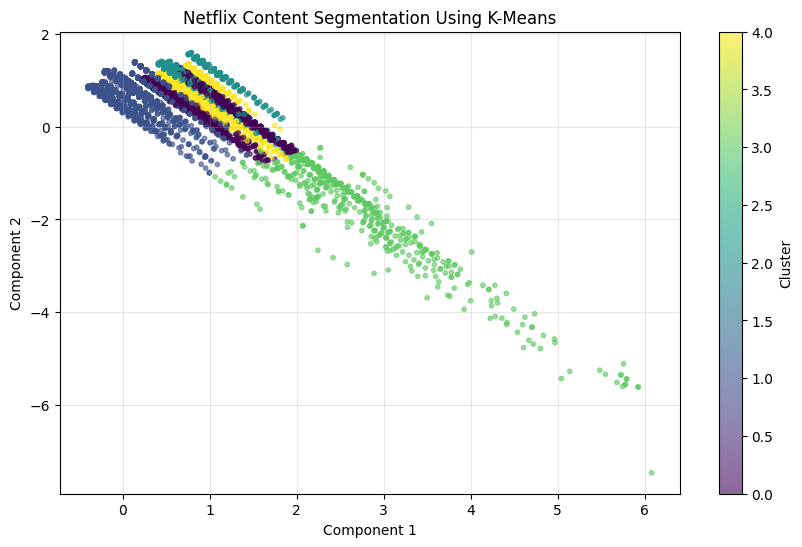

Explained Variance Ratio: 0.2908


In [12]:
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD

# 1. Reduce data to 2 dimensions
svd = TruncatedSVD(n_components=2, random_state=42)

X_2d = svd.fit_transform(X_processed)

# 2. Create a scatter plot
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=clusters,
    cmap="viridis",
    s=10,
    alpha=0.6
)

# 3. Add graph details
plt.title("Netflix Content Segmentation Using K-Means")
plt.xlabel("Component 1")
plt.ylabel("Component 2")

plt.colorbar(scatter, label="Cluster")

plt.grid(alpha=0.3)
plt.show()

# 4. Display explained variance
print(
    "Explained Variance Ratio:",
    round(svd.explained_variance_ratio_.sum(), 4)
)

INTERPRET CLUSTER CHARACTERISTICS

In [13]:
cluster_summary = []

for cluster_id in sorted(df_clustered["cluster"].unique()):

    cluster_data = df_clustered[
        df_clustered["cluster"] == cluster_id
    ]

    # Most common content type
    dominant_type = cluster_data["type"].mode()[0]

    # Average release year
    average_year = round(
        cluster_data["release_year"].mean(), 2
    )

    # Most common rating
    common_rating = cluster_data["rating"].mode()[0]

    # Most common country
    common_country = cluster_data["country"].mode()[0]

    # Most common genre
    genres = (
        cluster_data["listed_in"]
        .str.split(", ")
        .explode()
    )

    common_genre = genres.mode()[0]

    cluster_summary.append({
        "Cluster": cluster_id,
        "Total Titles": len(cluster_data),
        "Dominant Type": dominant_type,
        "Average Release Year": average_year,
        "Most Common Rating": common_rating,
        "Most Common Country": common_country,
        "Most Common Genre": common_genre
    })

# Display cluster interpretation
cluster_summary_df = pd.DataFrame(cluster_summary)

display(cluster_summary_df)

,Cluster,Total Titles,Dominant Type,Average Release Year,Most Common Rating,Most Common Country,Most Common Genre
0,0,2311,Movie,2014.40,R,United States,Dramas
1,1,2613,TV Show,2017.18,TV-MA,United States,International TV Shows
2,2,2003,Movie,2016.84,TV-MA,United States,International Movies
3,3,555,Movie,1986.80,TV-14,United States,Dramas
4,4,1308,Movie,2015.37,TV-14,India,International Movies
